# Sports Edge Lab: an engineering review

This notebook has two distinct evidence sources: an executable synthetic ML example and a sanitized aggregate export from real owner runs. Synthetic training does not reproduce the private football scores.

[Project overview](../README.md) · [Model card](../docs/MODEL_CARD_CURRENT.md) · [Reproduction instructions](../examples/review_lab/README.md)

The review follows chronology, matched scoring, failure behavior, recovery and the limits of current research evidence.

In [1]:
from pathlib import Path
import json, sys, tempfile
from IPython.display import HTML, SVG, display

root = Path.cwd().resolve()
while not (root / "examples/review_lab/core.py").exists():
    if root == root.parent:
        raise RuntimeError("Run this notebook from the repository")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from examples.review_lab.core import run_synthetic, synthetic_events, validate_rows, write_run
print({"project": "Sports Edge Lab", "python": sys.version.split()[0], "training_data": "synthetic"})

{'project': 'Sports Edge Lab', 'python': '3.12.14', 'training_data': 'synthetic'}


## 1. Fit on the past, evaluate the future

The example generates invented events with a learnable interaction. Two fixed logistic models fit the first 240 events; all three forecast systems are scored on the same 80 later events. This is an educational mechanism demonstration, not evidence that a particular football feature works.

In [2]:
synthetic = run_synthetic()
assert synthetic["data_kind"] == "synthetic"
assert not synthetic["real_football_performance"]
print(json.dumps({"training_rows": synthetic["training_rows"], "evaluation_rows": synthetic["evaluation_rows"], "scores": synthetic["scores"]}, indent=2))

{
  "training_rows": 240,
  "evaluation_rows": 80,
  "scores": {
    "MARKET_synthetic": {
      "games": 80,
      "log_loss": 0.7270739435856365,
      "brier": 0.26094180912467435,
      "accuracy": 0.575,
      "cohort_sha256": "c6a559a4fd866885d1a0691bada9a3a29732272acd01d433a36bff6795c1e246"
    },
    "additive": {
      "games": 80,
      "log_loss": 0.6733032443977589,
      "brier": 0.2396667073818856,
      "accuracy": 0.5875,
      "cohort_sha256": "c6a559a4fd866885d1a0691bada9a3a29732272acd01d433a36bff6795c1e246"
    },
    "joint": {
      "games": 80,
      "log_loss": 0.6725218345215374,
      "brier": 0.2392005590152248,
      "accuracy": 0.625,
      "cohort_sha256": "c6a559a4fd866885d1a0691bada9a3a29732272acd01d433a36bff6795c1e246"
    }
  }
}


## 2. Make invalid histories fail

This deliberately changes a feature's observation time to the event itself. Admission must reject it. The source row is synthetic and the original example remains unchanged.

In [3]:
invalid = synthetic_events(40)
invalid[0]["features_observed_at"] = invalid[0]["event_at"]
try:
    validate_rows(invalid)
except ValueError as error:
    print("EXPECTED REJECTION:", str(error))
else:
    raise AssertionError("Future information was admitted")

EXPECTED REJECTION: information-time contract violated


## 3. Reuse accepted work without another fit

The first invocation writes a report and digest manifest. The second verifies the artifact and reuses it. Incompatible configurations and corrupt files are covered by the unit tests.

In [4]:
with tempfile.TemporaryDirectory() as directory:
    output = Path(directory) / "accepted"
    first = write_run(output)
    second = write_run(output)
    assert first["new_fits"] == 2 and second["new_fits"] == 0
    assert first["report_sha256"] == second["report_sha256"]
    print({"first_status": first["status"], "second_status": second["status"], "second_new_fits": second["new_fits"], "same_artifact": True})

{'first_status': 'CREATED', 'second_status': 'REUSED', 'second_new_fits': 0, 'same_artifact': True}


## 4. Inspect real-run aggregates separately

The following table comes from the committed public evidence export. No model is fitted to these aggregates. Current monitoring ends October 15, 2026; retained references were selected on exposed results. Both latest historical challenger qualification gates failed.

In [5]:
evidence = json.loads((root / "docs/evidence/2026-10-26.json").read_text())
assert evidence["data_kind"] == "aggregate_private_run_export"
head = "<table><caption>Matched log loss; lower is better</caption><thead><tr><th>Sport / campaign</th><th>Games</th><th>MARKET</th><th>Challenger</th><th>Retained reference</th></tr></thead><tbody>"
rows = []
for row in evidence["rows"]:
    rows.append("<tr><td>{} {}</td><td>{}</td><td>{:.6f}</td><td>{:.6f}</td><td>{:.6f}</td></tr>".format(row["sport"], row["campaign"], row["games"], row["market"]["logloss"], row["challenger"]["logloss"], row["retained_log_loss_reference"]["logloss"]))
display(HTML(head + "".join(rows) + "</tbody></table>"))
print(evidence["selection_warning"])

Retained references were selected on already exposed results. These are descriptive comparisons, not untouched confirmation or proven profit.


Sport / campaign,Games,MARKET,Challenger,Retained reference
NFL 2024–2025 fixed,280,0.590011,0.587995,0.575083
NFL 2025–2026 fixed,277,0.611923,0.615619,0.606098
NFL 2025–2026 annual,277,0.611923,0.620113,0.606098
NFL 2026–2027 monitoring,77,0.660022,0.654224,0.624093
FBS 2024–2025 fixed,740,0.554096,0.556444,0.552031
FBS 2025–2026 fixed,748,0.538547,0.539773,0.536814
FBS 2025–2026 annual,748,0.538547,0.538394,0.535618
FBS 2026–2027 monitoring,301,0.474843,0.475016,0.465519


## 5. Read the current-season gap with its limits

The chart uses a zero-based log-loss scale. It compares selected retained references with MARKET, not a hypothetical profit curve. NFL has only six weekly blocks; FBS has eight. The public export contains exact metrics, policy differences and uncertainty limitations.

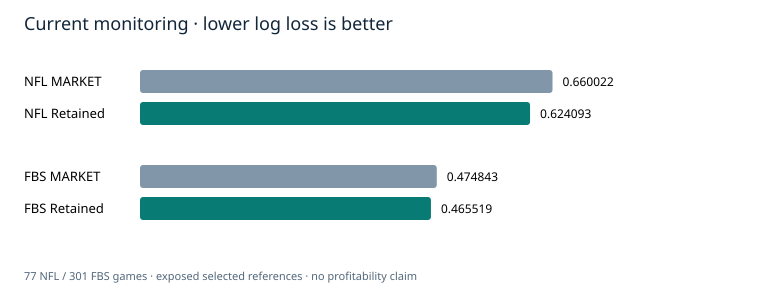

In [6]:
current = [r for r in evidence["rows"] if r["campaign"].startswith("2026")]
svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="760" height="300" viewBox="0 0 760 300" role="img"><title>Selected current-season log loss against MARKET</title><rect width="760" height="300" fill="#ffffff"/><text x="24" y="30" font-family="sans-serif" font-size="18" fill="#12263a">Current monitoring · lower log loss is better</text>']
for i, row in enumerate(current):
    for j, (label, key, color) in enumerate([("MARKET", "market", "#8196a8"), ("Retained", "retained_log_loss_reference", "#087c74")]):
        value = row[key]["logloss"]
        y = 70 + i * 95 + j * 32
        width = 500 * value / 0.8
        svg.append(f'<text x="24" y="{y+16}" font-family="sans-serif" font-size="13">{row["sport"]} {label}</text><rect x="140" y="{y}" width="{width:.3f}" height="23" rx="3" fill="{color}"/><text x="{150+width:.3f}" y="{y+16}" font-family="sans-serif" font-size="12">{value:.6f}</text>')
svg.append('<text x="24" y="280" font-family="sans-serif" font-size="11" fill="#52677a">77 NFL / 301 FBS games · exposed selected references · no profitability claim</text></svg>')
display(SVG("".join(svg)))

## 6. Connect successful serving to honest abstention

V119R1 reused controls, completed an integrated experiment, and issued research forecasts. Stale source prices kept action admission closed. Counts of forecast rows are not counts of independent games, and an operational improvement is not a new predictive gain.

In [7]:
execution = evidence["current_execution"]
print(json.dumps({k: execution[k] for k in ["version", "tests_passed", "real_fits", "research_forecast_rows", "unique_forecast_games", "fresh_named_quotes", "paper_actions", "actual_wagers"]}, indent=2))
assert execution["actual_wagers"] == 0


{
  "version": "V119R1",
  "tests_passed": 1142,
  "real_fits": 96,
  "research_forecast_rows": 3270,
  "unique_forecast_games": 52,
  "fresh_named_quotes": 0,
  "paper_actions": 0,
  "actual_wagers": 0
}


## 7. Recover two parents without expanding trust

The invented bundles below share a relative filename but have distinct logical parents and content hashes. Relocation preserves source identity and observation time. Omitting the second parent reproduces a source-admission failure; admitting its exact pinned manifest permits recovery; changing content afterward still fails.

This is a separate public implementation, not the private football resolver. It requires an immutable local cache and does not claim to defend against hostile concurrent filesystem mutation.


In [8]:
from examples.review_lab.provenance import demonstration
recovery = demonstration()
assert recovery["data_kind"] == "synthetic" and recovery["new_fits"] == 0
assert recovery["values"] == [7, 11]
assert recovery["observation_clocks_preserved"]
display(HTML("<table><caption>Invented provenance recovery</caption><tr><th>Case</th><th>Outcome</th></tr>"
             "<tr><td>Second parent omitted</td><td>Rejected before use</td></tr>"
             "<tr><td>Both pinned parents admitted after relocation</td><td>Verified values: 7 and 11</td></tr>"
             "<tr><td>One member changed afterward</td><td>Rejected by content identity</td></tr>"
             "<tr><td>Source clocks</td><td>Preserved; no backdating</td></tr></table>"))
print(json.dumps(recovery, indent=2))


{
  "schema": "sports-edge-provenance-demo-v1",
  "data_kind": "synthetic",
  "new_fits": 0,
  "network_calls": 0,
  "omitted_parent": "referenced parent was not admitted",
  "parents_recovered": [
    "alpha",
    "beta"
  ],
  "same_relative_key_scoped_by_parent": true,
  "observation_clocks_preserved": true,
  "values": [
    7,
    11
  ],
  "tampered_content": "artifact content identity mismatch",
  "claim": "Synthetic contract demonstration; private repair and owner execution remain separate."
}


Case,Outcome
Second parent omitted,Rejected before use
Both pinned parents admitted after relocation,Verified values: 7 and 11
One member changed afterward,Rejected by content identity
Source clocks,Preserved; no backdating


## 8. Separate passing checks from completed research

The following is the sanitized owner-run status, not output from the synthetic recovery example. V119 passed its checks but stopped at source admission before any real fit or public data refresh. Its modeling hypothesis is still unevaluated, and the earlier aggregate scorecard is unchanged. The [case study](../docs/CASE_STUDY_PROVENANCE.md) explains why the additional integration topology matters.


In [9]:
latest = json.loads((root / "docs/evidence/2026-10-26-execution.json").read_text())
assert latest["version"] == "V119" and latest["status"] == "FAILED"
assert latest["real_fit_attempts"] == 0 and not latest["predictive_metrics_changed"]
assert latest["qualification_result"] == "NOT_EVALUATED"
print(json.dumps({key: latest[key] for key in ["version", "status", "failure_class", "owner_tests_passed",
      "owner_separate_kernel_gate", "real_fit_attempts", "completed_real_fits", "qualification_result",
      "predictive_metrics_changed"]}, indent=2))


{
  "version": "V119",
  "status": "FAILED",
  "failure_class": "SOURCE_STATE",
  "owner_tests_passed": 1058,
  "owner_separate_kernel_gate": "PASS",
  "real_fit_attempts": 0,
  "completed_real_fits": 0,
  "qualification_result": "NOT_EVALUATED",
  "predictive_metrics_changed": false
}


## 9. Inspect the actual corrected owner outcome

V119R1 completed the work that failed in V119. Execution success and a negative scientific result coexist: all 96 new fits completed, but both historical qualification gates failed. The private prediction audit matched every exported score; the public notebook reads aggregate evidence only.


In [10]:
corrected = json.loads((root / "docs/evidence/2026-10-26-v119r1-execution.json").read_text())
assert corrected["status"] == "SUCCESS" and corrected["completed_real_fits"] == 96
assert not any(corrected["historical_candidate_gate"].values())
assert corrected["automatic_promotions"] == 0 and corrected["actual_wagers"] == 0
print(json.dumps({k:corrected[k] for k in ["version","status","scientific_result","completed_real_fits","completed_study_cells","historical_candidate_gate"]}, indent=2))


{
  "version": "V119R1",
  "status": "SUCCESS",
  "scientific_result": "VALID_NEGATIVE",
  "completed_real_fits": 96,
  "completed_study_cells": 192,
  "historical_candidate_gate": {
    "NFL": false,
    "FBS": false
  }
}


## 10. Evaluate complementarity separately from superiority

These three score fixtures are invented. Their probabilities are assigned relative to known invented labels for transparent arithmetic; they do not simulate genuine pregame forecasting. The generic evaluator verifies identical cohorts and estimates paired block intervals. A negative interaction alone cannot override a loss against MARKET or the retained reference.


In [11]:
from examples.review_lab.factorial import evaluate, fixture
joint = {name:evaluate(fixture(name)) for name in ["complementary","redundant","harmful"]}
assert joint["complementary"]["descriptive_joint_evidence"]
assert not joint["redundant"]["descriptive_joint_evidence"]
assert not joint["harmful"]["descriptive_joint_evidence"]
rows = "".join("<tr><th>"+name+"</th><td>"+format(result["interaction"]["estimate"],"+.6f")+"</td><td>"+str(result["descriptive_joint_evidence"])+"</td></tr>" for name,result in joint.items())
display(HTML("<table><caption>Invented factorial score fixtures, not football results</caption><thead><tr><th>Fixture</th><th>Interaction log loss</th><th>Descriptive joint evidence</th></tr></thead><tbody>"+rows+"</tbody></table>"))


Fixture,Interaction log loss,Descriptive joint evidence
complementary,-0.130561,True
redundant,+0.049291,False
harmful,+0.250045,False


## 11. A new target does not guarantee a better forecast

V120 completed 48 new score-distribution fits and reused 192 retained comparison cells. Both historical candidate and season-stability gates failed. This aggregate-only view compares conditional-win probabilities on the same non-tied games. Joint score-law comparisons include ties and have a different target.


Sport / campaign,Games,MARKET raw,Retained leader,D0 ensemble,D1 ensemble
NFL / 2024–2025 fixed,280,0.590011,0.575083,0.672637,0.696305
NFL / 2025–2026 fixed,277,0.611923,0.606098,0.745526,0.795849
NFL / 2025–2026 annual,277,0.611923,0.606098,0.669268,0.675059
NFL / 2026–2027 monitoring,77,0.660022,0.624093,0.643245,0.651836
FBS / 2024–2025 fixed,740,0.554096,0.552031,0.574150,0.576601
FBS / 2025–2026 fixed,748,0.538547,0.536814,0.556603,0.564830
FBS / 2025–2026 annual,748,0.538547,0.535618,0.543917,0.544839
FBS / 2026–2027 monitoring,301,0.474843,0.465519,0.474858,0.481886


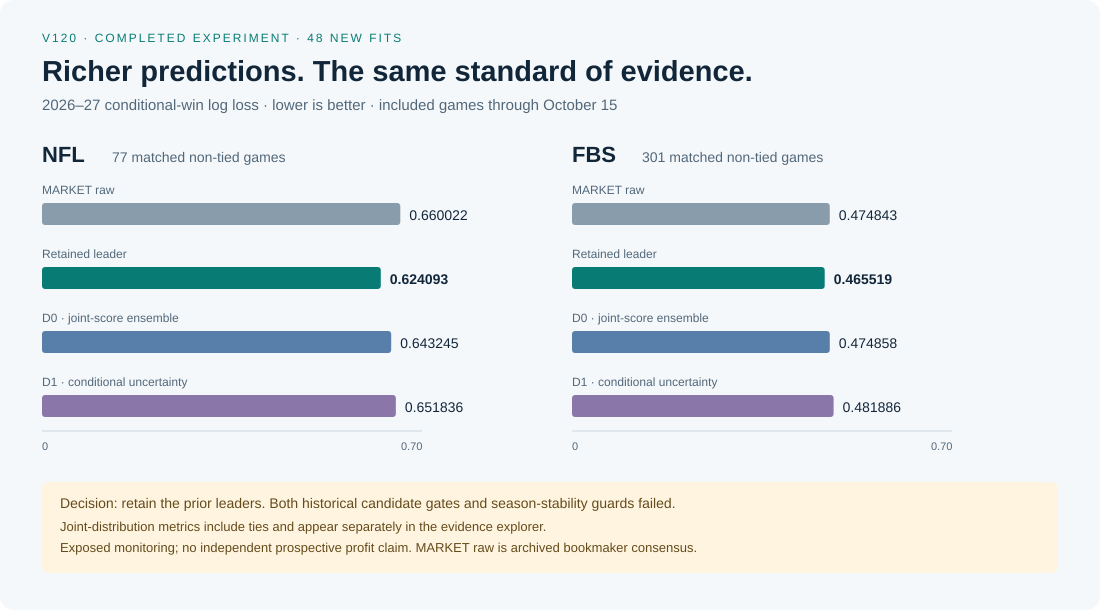

In [12]:
score_laws = json.loads((root / "docs/evidence/2026-10-26-v120.json").read_text())
assert score_laws["current_execution"]["real_fits"] == 48
assert not any(score_laws["distribution_contract"]["historical_candidate_gate"].values())
table = ["<table><caption>V120 conditional win log loss · matched exposed cohorts</caption><thead><tr><th>Sport / campaign</th><th>Games</th><th>MARKET raw</th><th>Retained leader</th><th>D0 ensemble</th><th>D1 ensemble</th></tr></thead><tbody>"]
for row in score_laws["rows"]:
    values = [row["market"]["logloss"], row["retained_log_loss_reference"]["logloss"], row["score_law_binary"]["Ensemble D0"]["logloss"], row["score_law_binary"]["Ensemble D1"]["logloss"]]
    table.append("<tr><td>"+row["sport"]+" / "+row["campaign"]+"</td><td>"+str(row["games"])+"</td>"+"".join("<td>"+("<b>" if v==min(values) else "")+f"{v:.6f}"+("</b>" if v==min(values) else "")+"</td>" for v in values)+"</tr>")
display(HTML("".join(table)+"</tbody></table>"))
display(SVG((root / "docs/assets/evidence-overview.svg").read_text()))


## 12. Reproduce numerical mechanics with invented laws

These tiny laws are specified, not fitted. Their tie probabilities differ. Mixing full probability laws and then conditioning differs from averaging already conditioned win probabilities. Expected contract settlement also depends on the tie payout; it excludes purchase cost and fees here. None of these numbers are football forecasts.


In [13]:
from examples.review_lab.distribution import demonstration as distribution_demonstration
distribution_demo = distribution_demonstration()
assert not distribution_demo["real_football_performance"]
assert distribution_demo["mixture_then_condition_home"] != distribution_demo["incorrect_average_of_conditional_home"]
assert not distribution_demo["purchase_price_and_fees_included"]
print(json.dumps(distribution_demo, indent=2))


{
  "data_kind": "invented_probability_laws",
  "real_football_performance": false,
  "joint_mixture_outcomes": {
    "home": 0.275,
    "away": 0.425,
    "tie": 0.30000000000000004
  },
  "mixture_then_condition_home": 0.39285714285714296,
  "incorrect_average_of_conditional_home": 0.5055555555555555,
  "unit_contract_half_tie_expected_settlement": 0.42500000000000004,
  "purchase_price_and_fees_included": false
}


## 13. Count new outcomes instead of repeated forecast rows

The newest settled archive has 6,755 forecast rows but only 56 unique game outcomes. Exact fitted model versions and issue horizons remain separate. The rows below compare each model against raw MARKET on its own exact same-issue cohort; they are not an interchangeable leaderboard. Model-family comparisons remain retrospective, and no new V120 distribution forecast has settled in this return.


In [14]:
recent = json.loads((root / "docs/evidence/2026-10-26-recent-settlements.json").read_text())
assert recent["unique_settled_games"] == 56
assert recent["new_V120_score_laws_with_settled_forecasts"] == 0
assert not recent["profit_established"] and not recent["individual_predictions_exported"]
print(json.dumps({"raw_forecast_rows":recent["raw_archived_forecast_rows"], "unique_games":recent["unique_games_by_sport"], "exact_model_groups":recent["exact_model_groups"]}, indent=2))
for row in recent["rows"]:
    print(row["model_id"], row["n"], "model log loss", round(row["model"]["win_logloss"],6), "MARKET log loss", round(row["MARKET_raw_same_issue_same_games"]["win_logloss"],6), "weekly blocks",row["utc_week_blocks"])


{
  "raw_forecast_rows": 6755,
  "unique_games": {
    "ncaaf": 44,
    "nfl": 12
  },
  "exact_model_groups": 176
}
retained_fixed_ncaaf_tf_family_base 3 model log loss 0.453486 MARKET log loss 0.465058 weekly blocks 1
upcoming_ncaaf_ensemble_joint_feedback_recent 44 model log loss 0.627104 MARKET log loss 0.625157 weekly blocks 1
upcoming_ncaaf_tf_family_base 44 model log loss 0.603075 MARKET log loss 0.625157 weekly blocks 1
retained_weekly_nfl_torch_joint_feedback_recent 12 model log loss 0.669402 MARKET log loss 0.695898 weekly blocks 2
upcoming_nfl_ensemble_joint_feedback_recent 12 model log loss 0.702977 MARKET log loss 0.70422 weekly blocks 2
upcoming_nfl_torch_joint_feedback_recent 12 model log loss 0.723284 MARKET log loss 0.70422 weekly blocks 2


In [15]:
assert len(evidence["rows"]) == 8
assert recovery["new_fits"] == 0 and latest["actual_wagers"] == 0
print("PUBLIC_REVIEW_COMPLETE: all cells finished; synthetic fitting, provenance behavior and owner evidence remain distinct.")


PUBLIC_REVIEW_COMPLETE: all cells finished; synthetic fitting, provenance behavior and owner evidence remain distinct.


## What to inspect next

- [Current evidence and uncertainty](../docs/CURRENT_EVIDENCE.md)
- [System contracts and trade-offs](../docs/SYSTEM_DESIGN.md)
- [Publication boundary](../docs/PUBLICATION_BOUNDARY.md)
- [Behavioral tests](../examples/review_lab/tests/test_core.py)

The private recipe, licensed observations, weights and individual predictions are intentionally absent. This notebook demonstrates executable engineering and clearly scoped evidence, not independent reproduction of the private model scores.